## CL-1 Lab Assignment 6 (Group A) : Reinforcement Learning
### Building a Tic-Tac-Toe game using reinforcement learning in Python.

In [7]:
import numpy as np
import pandas as pd
import random
from collections import defaultdict
import matplotlib.pyplot as plt

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


In [8]:
class TicTacToe:
    def __init__(self):
        self.reset()

    def reset(self):
        self.board = np.zeros(9, dtype=np.int8)
        self.current_player = 1
        return self.get_state()

    def get_state(self):
        return tuple(self.board.tolist())

    def available_actions(self):
        return [i for i, value in enumerate(self.board) if value == 0]

    def check_winner(self):
        winning_lines = [
            (0, 1, 2), (3, 4, 5), (6, 7, 8),
            (0, 3, 6), (1, 4, 7), (2, 5, 8),
            (0, 4, 8), (2, 4, 6)
        ]

        for a, b, c in winning_lines:
            if self.board[a] != 0 and self.board[a] == self.board[b] == self.board[c]:
                return int(self.board[a])

        if not self.available_actions():
            return 0  # draw

        return None  # game continues

    def step(self, action):
        if action not in self.available_actions():
            raise ValueError("Invalid action: position is already occupied.")

        player = self.current_player
        self.board[action] = player

        result = self.check_winner()

        if result is None:
            self.current_player *= -1
            done = False
        else:
            done = True

        return self.get_state(), result, done

    def render(self):
        symbols = {1: "X", -1: "O", 0: " "}
        rows = []
        for i in range(0, 9, 3):
            rows.append(" | ".join(symbols[int(v)] for v in self.board[i:i+3]))
        print("\n---------\n".join(rows))


env = TicTacToe()
print("Initial state:", env.get_state())
print("Available actions:", env.available_actions())
env.render()

Initial state: (0, 0, 0, 0, 0, 0, 0, 0, 0)
Available actions: [0, 1, 2, 3, 4, 5, 6, 7, 8]
  |   |  
---------
  |   |  
---------
  |   |  


In [9]:
# Quick rule test: X wins across the first row.
test_env = TicTacToe()
for action in [0, 3, 1, 4, 2]:
    state, result, done = test_env.step(action)

test_env.render()
print("\nWinner:", "X" if result == 1 else "O" if result == -1 else "Draw" if result == 0 else "None")
print("Game over:", done)

X | X | X
---------
O | O |  
---------
  |   |  

Winner: X
Game over: True


In [10]:
class QLearningAgent:
    def __init__(
        self,
        alpha=0.2,
        gamma=0.95,
        epsilon=1.0,
        epsilon_min=0.05,
        epsilon_decay=0.9995
    ):
        self.q_table = defaultdict(lambda: np.zeros(9, dtype=np.float64))
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay

    def choose_action(self, state, available_actions, training=True):
        if training and random.random() < self.epsilon:
            return random.choice(available_actions)

        q_values = self.q_table[state]
        available_q = np.array([q_values[a] for a in available_actions])
        max_q = np.max(available_q)

        # Random tie-breaking among equally good actions
        best_actions = [
            action for action in available_actions
            if q_values[action] == max_q
        ]
        return random.choice(best_actions)

    def update(self, state, action, reward, next_state, next_actions, done):
        current_q = self.q_table[state][action]

        if done:
            target = reward
        else:
            next_max = max(self.q_table[next_state][a] for a in next_actions)
            target = reward + self.gamma * next_max

        self.q_table[state][action] += self.alpha * (target - current_q)

    def decay_exploration(self):
        self.epsilon = max(
            self.epsilon_min,
            self.epsilon * self.epsilon_decay
        )


agent_x = QLearningAgent()
agent_o = QLearningAgent()

print("Q-learning agents created.")
print("Initial X epsilon:", agent_x.epsilon)

Q-learning agents created.
Initial X epsilon: 1.0


In [11]:
def train_self_play(agent_x, agent_o, episodes=20000):
    history = {
        "x_wins": [],
        "o_wins": [],
        "draws": [],
        "epsilon_x": []
    }

    block_x = block_o = block_draw = 0

    for episode in range(1, episodes + 1):
        env = TicTacToe()
        state = env.get_state()

        # Store each player's most recent action until the opponent moves.
        last_transition = {1: None, -1: None}

        while True:
            player = env.current_player
            agent = agent_x if player == 1 else agent_o

            available = env.available_actions()
            action = agent.choose_action(state, available, training=True)
            next_state, result, done = env.step(action)

            # The action made by the opponent on the previous turn now has
            # a known next state and (unless the game ends) zero immediate reward.
            opponent = -player
            if last_transition[opponent] is not None:
                prev_state, prev_action = last_transition[opponent]
                agent_opponent = agent_o if opponent == -1 else agent_x

                if done:
                    # If the current player won, the opponent lost.
                    opponent_reward = -1 if result == player else 0
                    agent_opponent.update(
                        prev_state, prev_action, opponent_reward,
                        next_state, [], True
                    )
                else:
                    agent_opponent.update(
                        prev_state, prev_action, 0,
                        next_state, env.available_actions(), False
                    )

            if done:
                # Current player's move caused the terminal outcome.
                current_reward = 1 if result == player else 0
                agent.update(
                    state, action, current_reward,
                    next_state, [], True
                )

                if result == 1:
                    block_x += 1
                elif result == -1:
                    block_o += 1
                else:
                    block_draw += 1
                break

            # Hold current player's transition until the opponent acts.
            last_transition[player] = (state, action)
            state = next_state

        agent_x.decay_exploration()
        agent_o.decay_exploration()

        if episode % 100 == 0:
            history["x_wins"].append(block_x)
            history["o_wins"].append(block_o)
            history["draws"].append(block_draw)
            history["epsilon_x"].append(agent_x.epsilon)
            block_x = block_o = block_draw = 0

    return history


history = train_self_play(agent_x, agent_o, episodes=20000)

print("Training completed.")
print("States learned by X:", len(agent_x.q_table))
print("States learned by O:", len(agent_o.q_table))
print("Final epsilon:", round(agent_x.epsilon, 4))

Training completed.
States learned by X: 2181
States learned by O: 1907
Final epsilon: 0.05


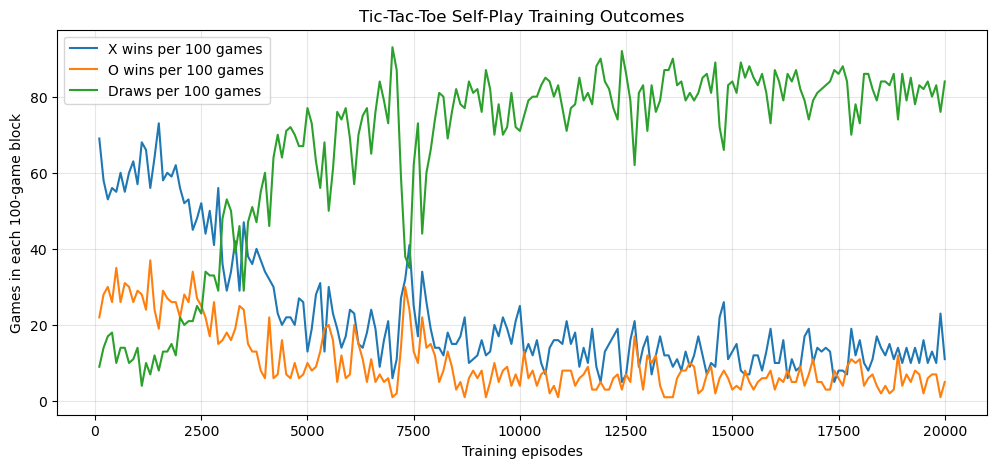

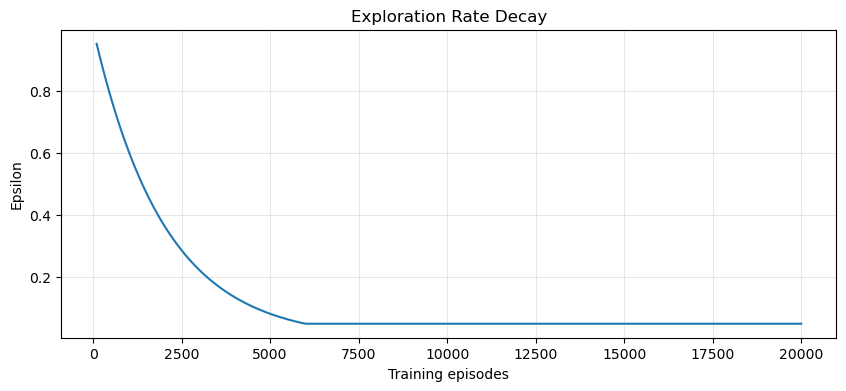

In [12]:
episodes_per_point = np.arange(100, 20001, 100)

plt.figure(figsize=(12, 5))
plt.plot(episodes_per_point, history["x_wins"], label="X wins per 100 games")
plt.plot(episodes_per_point, history["o_wins"], label="O wins per 100 games")
plt.plot(episodes_per_point, history["draws"], label="Draws per 100 games")
plt.xlabel("Training episodes")
plt.ylabel("Games in each 100-game block")
plt.title("Tic-Tac-Toe Self-Play Training Outcomes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(episodes_per_point, history["epsilon_x"])
plt.xlabel("Training episodes")
plt.ylabel("Epsilon")
plt.title("Exploration Rate Decay")
plt.grid(alpha=0.3)
plt.show()

In [13]:
def play_against_random(agent, games=1000):
    wins = losses = draws = 0

    for _ in range(games):
        env = TicTacToe()
        state = env.get_state()

        while True:
            if env.current_player == 1:
                action = agent.choose_action(
                    state, env.available_actions(), training=False
                )
            else:
                action = random.choice(env.available_actions())

            next_state, result, done = env.step(action)
            state = next_state

            if done:
                if result == 1:
                    wins += 1
                elif result == -1:
                    losses += 1
                else:
                    draws += 1
                break

    return wins, losses, draws


test_games = 1000
wins, losses, draws = play_against_random(agent_x, games=test_games)

test_results = pd.Series({
    "Wins": wins,
    "Losses": losses,
    "Draws": draws,
    "Win Rate": wins / test_games,
    "Draw Rate": draws / test_games,
    "Non-loss Rate": (wins + draws) / test_games
})

display(test_results.to_frame("Value").style.format({
    "Value": lambda x: f"{x:.4f}" if isinstance(x, float) else f"{int(x)}"
}))

,Value
Wins,844.0000
Losses,51.0000
Draws,105.0000
Win Rate,0.8440
Draw Rate,0.1050
Non-loss Rate,0.9490


In [14]:
def play_demo(agent):
    env = TicTacToe()
    state = env.get_state()

    print("Demo game: trained X agent vs random O")
    env.render()

    while True:
        if env.current_player == 1:
            action = agent.choose_action(
                state, env.available_actions(), training=False
            )
            print(f"\nAgent X chooses position {action + 1}")
        else:
            action = random.choice(env.available_actions())
            print(f"\nRandom O chooses position {action + 1}")

        state, result, done = env.step(action)
        env.render()

        if done:
            if result == 1:
                print("\nResult: X (trained agent) wins.")
            elif result == -1:
                print("\nResult: O (random opponent) wins.")
            else:
                print("\nResult: Draw.")
            break

play_demo(agent_x)

Demo game: trained X agent vs random O
  |   |  
---------
  |   |  
---------
  |   |  

Agent X chooses position 4
  |   |  
---------
X |   |  
---------
  |   |  

Random O chooses position 1
O |   |  
---------
X |   |  
---------
  |   |  

Agent X chooses position 5
O |   |  
---------
X | X |  
---------
  |   |  

Random O chooses position 3
O |   | O
---------
X | X |  
---------
  |   |  

Agent X chooses position 6
O |   | O
---------
X | X | X
---------
  |   |  

Result: X (trained agent) wins.
